# 道路落石与滑坡检测 — YOLO 目标检测「训练 / 评价 / 可视化」全流程

> **数据集**：*Street-level and aerial images of rockfall and landslide events on roads, annotated for object detection to identify debris, boulders and terrain instability.*
> 来源 `rockfall.ndjson`（Ultralytics 平台 `vic-vulture/rockfall`，约 405 MB，1964 张图像、3 个类别）。
>
> **类别**：`0 rockfall`（落石） · `1 landslides`（滑坡） · `2 隧道`（隧道）
>
> **本 Notebook 覆盖（面向 SCI 论文的完整实验流水线）**
> | 章节 | 内容 |
> |---|---|
> | 1 | 环境与可复现性（随机种子 / GPU / 版本） |
> | 2 | 数据构建：解析 ndjson → 下载图像 → 生成 YOLO 标签与 `data.yaml` |
> | 3 | 数据集探索分析（EDA）：划分统计、类别不平衡、目标尺寸分布、标注可视化 |
> | 4 | 模型训练：YOLO11 迁移学习 + 数据增强 + 余弦学习率 + warm-up，**逐 step/逐 epoch 回调采集** |
> | 5 | **训练过程可视化**：逐步损失（梯度下降动态）、损失分解、mAP/P/R 曲线、**梯度范数与逐层梯度流**、学习率调度、每轮耗时 |
> | 6 | **模型评价**：P/R/F1、mAP@50、mAP@50-95、逐类指标、混淆矩阵、PR / F1-置信度曲线、检测结果画廊 |
> | 7 | 结果汇总与论文图表清单（高分辨率 PNG + CSV/JSON） |
>
> > ⚠️ 依赖：`ultralytics`、`torch`(CUDA)、`opencv-python`、`matplotlib`、`seaborn`、`pandas`、`pyyaml`。
> > 首次运行需联网下载数据集图像（~400 MB，之后自动跳过已存在文件）。本 Notebook 通过同目录下的
> > `rockfall_dataset.py` 与 `rockfall_training.py` 两个辅助模块复用可读性更高的函数。

## 1. 环境配置与可复现性

固定随机种子、把 Ultralytics 的 `runs/` 输出目录重定向到工程目录（便于移植与沙盒运行），
并设置论文级 Matplotlib 样式与中文字体，保证结果可复现、图表可直接用于论文。

In [2]:
import os, sys, json, time, random, warnings
from pathlib import Path

# 屏蔽 Ultralytics 自动升级提示、固定编码
os.environ.setdefault("YOLO_AUTOINSTALL", "false")
os.environ.setdefault("PYTHONIOENCODING", "utf-8")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt

# ---- 可复现性 ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ---- 训练产物重定向到工程目录（可移植）----
import ultralytics
from ultralytics import YOLO, settings
settings.update({"runs_dir": str(Path("runs").resolve())})

# ---- 论文级绘图样式 ----
%matplotlib inline
matplotlib.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.autolayout": True,
})
for _f in ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Arial Unicode MS"]:
    try:
        matplotlib.rcParams["font.sans-serif"] = [_f]
        break
    except Exception:
        pass
matplotlib.rcParams["axes.unicode_minus"] = False

# 结果目录
Path("figs").mkdir(exist_ok=True)

print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA可用:", torch.cuda.is_available(),
      "|", (torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"))
print("Ultralytics:", ultralytics.__version__)
print("runs_dir ->", settings["runs_dir"])

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("训练设备 DEVICE =", DEVICE)

Python : 3.12.10
PyTorch: 2.6.0+cu124 | CUDA可用: True | NVIDIA T1200 Laptop GPU
Ultralytics: 8.4.202
runs_dir -> C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\runs
训练设备 DEVICE = 0


## 2. 数据构建：从 `rockfall.ndjson` 到 YOLO 数据集

`rockfall.ndjson` 每行一个 JSON：
- 第 1 行：数据集元信息（`type="dataset"`，含 `class_names`、url、字节数）；
- 其余行：图像记录（`type="image"`），字段 `file / url / width / height / split / annotations.boxes`。
  每个框 `[cls, cx, cy, w, h]`，坐标已按图像尺寸归一化到 `[0,1]`（YOLO 中心点格式）。

下面先解析文件头验证记录合法，再调用 `rockfall_dataset.build_dataset` 下载图像、写出 YOLO 标签与 `data.yaml`（幂等，可重复运行）。

In [3]:
from rockfall_dataset import build_dataset, _read_records

NDJSON = Path("rockfall.ndjson")
DATA_ROOT = Path("datasets/rockfall")
DATA_YAML = DATA_ROOT / "data.yaml"

# ---- 解析记录、统计总量 ----
meta, images = _read_records(NDJSON)
class_names = {int(k): v for k, v in meta["class_names"].items()}
print("数据集名称 :", meta.get("name"))
print("类别        :", class_names)
print("图像总数    :", len(images))
print("声明体量    : %.1f MB" % (meta.get("bytes", 0) / 1e6))

数据集名称 : rockfall
类别        : {0: 'rockfall', 1: 'landslides', 2: '隧道'}
图像总数    : 1964
声明体量    : 405.2 MB


In [4]:
# ---- 下载图像 + 生成标签 + data.yaml（已存在则跳过）----
if not DATA_YAML.exists():
    stats = build_dataset(NDJSON, DATA_ROOT, workers=16)
else:
    stats = json.loads((DATA_ROOT / "dataset_stats.json").read_text(encoding="utf-8"))
    print("检测到已存在数据集，跳过下载。")
print("\n各划分统计：")
print(json.dumps(stats["splits"], indent=2, ensure_ascii=False))

检测到已存在数据集，跳过下载。

各划分统计：
{
  "train": {
    "images": 1316,
    "boxes": 3712,
    "per_class": {
      "0": 2675,
      "1": 1031,
      "2": 6
    }
  },
  "val": {
    "images": 390,
    "boxes": 814,
    "per_class": {
      "1": 338,
      "0": 476
    }
  },
  "test": {
    "images": 258,
    "boxes": 710,
    "per_class": {
      "1": 222,
      "0": 488
    }
  }
}


## 3. 探索性数据分析（EDA）

分析数据集规模、划分、类别不平衡与目标尺寸分布，为模型选择与数据增强提供依据。
（此类图常用于论文 *Dataset* 小节。）

In [5]:
import yaml
cfg = yaml.safe_load(open(DATA_YAML, encoding="utf-8"))
SPLITS = ["train", "val", "test"]
NAMES = cfg["names"]
CLASSES = [NAMES[i] for i in sorted(NAMES)]
NC = cfg["nc"]

rows, dist = [], {}
for s in SPLITS:
    img_dir = DATA_ROOT / "images" / s
    lbl_dir = DATA_ROOT / "labels" / s
    n_img = len(list(img_dir.glob("*.jpg")))
    n_box = 0; counts = {c: 0 for c in CLASSES}
    for f in lbl_dir.glob("*.txt"):
        for line in f.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 5:
                n_box += 1
                counts[CLASSES[int(float(parts[0]))]] += 1
    rows.append({"split": s, "images": n_img, "boxes": n_box,
                 "boxes/img": round(n_box / max(n_img, 1), 2)})
    dist[s] = counts

df_split = pd.DataFrame(rows)
print(df_split.to_string(index=False))
print("\n总体：%d 张图像, %d 个标注框" % (df_split.images.sum(), df_split.boxes.sum()))
df_cls = pd.DataFrame(dist).fillna(0).astype(int)
print("\n各类别标注框数（按划分）：")
print(df_cls.to_string())

split  images  boxes  boxes/img
train    1316   3712       2.82
  val     390    814       2.09
 test     258    710       2.75

总体：1964 张图像, 5236 个标注框

各类别标注框数（按划分）：
            train  val  test
rockfall     2675  476   488
landslides   1031  338   222
隧道              6    0     0


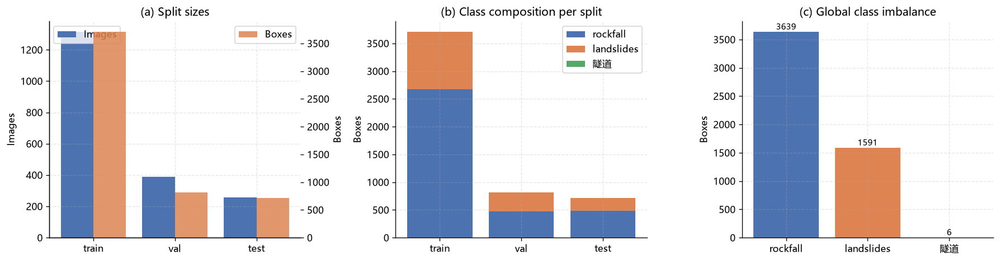

In [6]:
# ---- 图 3.1：划分规模 + 类别构成 + 全局类别不平衡 ----
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ax = axes[0]
x = np.arange(len(df_split))
ax.bar(x - 0.2, df_split.images, width=0.4, label="Images", color="#4C72B0")
ax2 = ax.twinx(); ax2.grid(False)
ax2.bar(x + 0.2, df_split.boxes, width=0.4, label="Boxes", color="#DD8452", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(df_split.split)
ax.set_ylabel("Images"); ax2.set_ylabel("Boxes"); ax.set_title("(a) Split sizes")
ax.legend(loc="upper left"); ax2.legend(loc="upper right")

ax = axes[1]
bottom = np.zeros(len(SPLITS)); colors = ["#4C72B0", "#DD8452", "#55A868"]
for ci, c in enumerate(CLASSES):
    vals = np.array([dist[s][c] for s in SPLITS])
    ax.bar(SPLITS, vals, bottom=bottom, label=c, color=colors[ci % len(colors)])
    bottom += vals
ax.set_ylabel("Boxes"); ax.set_title("(b) Class composition per split"); ax.legend()

ax = axes[2]
tot = df_cls.sum(axis=1)
bars = ax.bar(tot.index, tot.values, color=colors[:len(tot)])
ax.set_ylabel("Boxes"); ax.set_title("(c) Global class imbalance")
for b, v in zip(bars, tot.values):
    ax.text(b.get_x()+b.get_width()/2, v, str(int(v)), ha="center", va="bottom", fontsize=9)

plt.tight_layout(); plt.savefig("figs/eda_split_class.png", bbox_inches="tight"); plt.show()

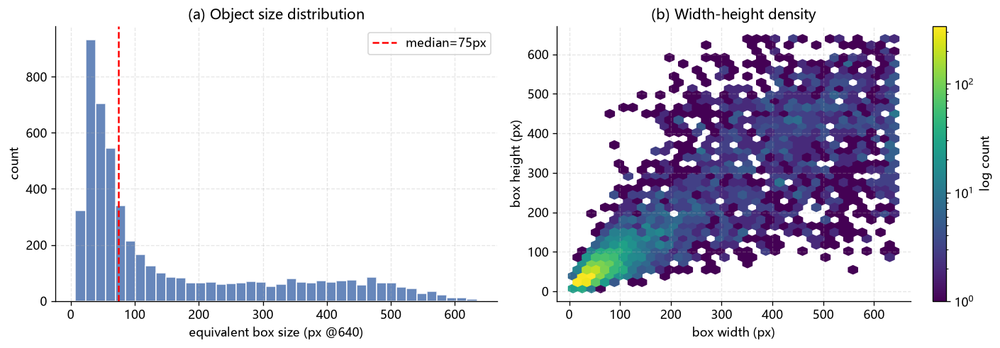

目标尺寸: 中位 75.0 px, 小目标(<32px)占比 16.0%


In [7]:
# ---- 图 3.2：目标框尺寸分布（像素，按 imgsz=640 换算）----
IMGSZ = 640
ws, hs = [], []
for s in SPLITS:
    for f in (DATA_ROOT / "labels" / s).glob("*.txt"):
        for line in f.read_text(encoding="utf-8").splitlines():
            p = line.split()
            if len(p) == 5:
                ws.append(float(p[3]) * IMGSZ); hs.append(float(p[4]) * IMGSZ)
ws, hs = np.array(ws), np.array(hs)
area = np.sqrt(ws * hs)  # 等效边长

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(area, bins=40, color="#4C72B0", alpha=0.85, edgecolor="white")
axes[0].axvline(np.median(area), color="red", ls="--", label=f"median={np.median(area):.0f}px")
axes[0].set_xlabel("equivalent box size (px @640)"); axes[0].set_ylabel("count")
axes[0].set_title("(a) Object size distribution"); axes[0].legend()

hb = axes[1].hexbin(ws, hs, gridsize=35, cmap="viridis", bins="log")
axes[1].set_xlabel("box width (px)"); axes[1].set_ylabel("box height (px)")
axes[1].set_title("(b) Width-height density")
fig.colorbar(hb, ax=axes[1], label="log count")
plt.tight_layout(); plt.savefig("figs/eda_box_size.png", bbox_inches="tight"); plt.show()
print("目标尺寸: 中位 %.1f px, 小目标(<32px)占比 %.1f%%" % (np.median(area), 100*(area < 32).mean()))

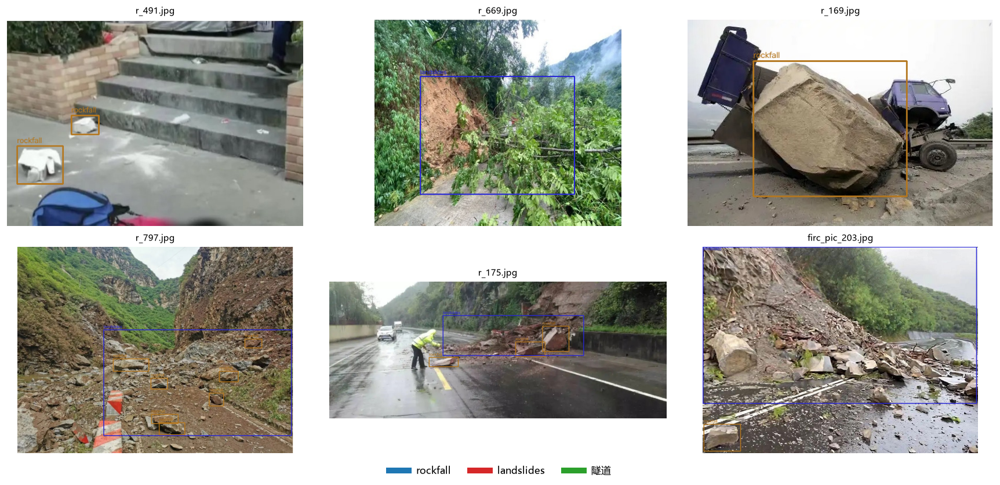

In [8]:
# ---- 图 3.3：标注可视化样例（train 随机 6 张）----
import cv2
def draw_gt(img_path, label_path, color_map):
    img = cv2.imread(str(img_path)); h, w = img.shape[:2]
    if Path(label_path).exists():
        for line in Path(label_path).read_text(encoding="utf-8").splitlines():
            p = line.split()
            if len(p) != 5: continue
            c = int(float(p[0])); cx, cy, bw, bh = map(float, p[1:])
            x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
            x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
            col = color_map[c % len(color_map)]
            cv2.rectangle(img, (x1, y1), (x2, y2), col, 2)
            cv2.putText(img, CLASSES[c], (x1, max(y1-5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

rng = np.random.default_rng(SEED)
train_imgs = sorted((DATA_ROOT / "images" / "train").glob("*.jpg"))
samples = rng.choice(train_imgs, size=6, replace=False)
c_map = [(31,119,180), (214,39,40), (44,160,44)]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, ip in zip(axes.ravel(), samples):
    lp = DATA_ROOT / "labels" / "train" / (ip.stem + ".txt")
    ax.imshow(draw_gt(ip, lp, c_map)); ax.set_title(ip.name, fontsize=9); ax.axis("off")
handles = [plt.Line2D([0],[0], color=np.array(c)/255, lw=6) for c in c_map]
fig.legend(handles, CLASSES, loc="lower center", ncol=len(CLASSES), frameon=False)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.savefig("figs/eda_annotations.png", bbox_inches="tight"); plt.show()

## 4. 模型训练

采用 **YOLO11n** 预训练权重做迁移学习，并借助 `rockfall_training.make_callbacks` 在训练过程中逐 step / 逐 epoch 采集：
总损失与分解损失、**梯度 L2 范数（整体 + 逐层）**、学习率、验证 mAP / P / R、每轮耗时。

> 💻 显存预算：本机 GPU 为 **NVIDIA T1200 / 4 GB**。默认 `imgsz=640, batch=8`；若 OOM 请把 `BATCH` 降到 4 或 2。
> ⏱️ 完整 60 轮在 4 GB 笔记本 GPU 上约需 1–2 小时；快速跑通可临时把 `EPOCHS` 设为 5–10。
> 所有训练超参数集中在 `CFG` 字典中，便于论文复现记录。

In [9]:
import rockfall_training as RT

CFG = dict(
    data=str(DATA_YAML),
    model="yolo11n.pt",        # 迁移学习起点（可换 yolo11s.pt 提升精度）
    epochs=60,
    imgsz=640,
    batch=8,
    device=DEVICE,
    optimizer="auto",          # AdamW(auto) + 余弦退火
    lr0=0.01, lrf=0.01,        # 初始 / 最终学习率比
    warmup_epochs=3.0,
    momentum=0.937, weight_decay=0.0005,
    # 数据增强
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=10.0, translate=0.1, scale=0.5, shear=2.0, perspective=0.0,
    flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.0,
    # 训练策略
    patience=20, seed=SEED,
    project=str(Path("runs").resolve()), name="yolo11n_rockfall",
    exist_ok=True, plots=True, verbose=True,
)
print("训练配置：")
for k, v in CFG.items():
    print(f"  {k:14s} = {v}")

训练配置：
  data           = datasets\rockfall\data.yaml
  model          = yolo11n.pt
  epochs         = 60
  imgsz          = 640
  batch          = 8
  device         = 0
  optimizer      = auto
  lr0            = 0.01
  lrf            = 0.01
  warmup_epochs  = 3.0
  momentum       = 0.937
  weight_decay   = 0.0005
  hsv_h          = 0.015
  hsv_s          = 0.7
  hsv_v          = 0.4
  degrees        = 10.0
  translate      = 0.1
  scale          = 0.5
  shear          = 2.0
  perspective    = 0.0
  flipud         = 0.0
  fliplr         = 0.5
  mosaic         = 1.0
  mixup          = 0.0
  patience       = 20
  seed           = 42
  project        = C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\runs
  name           = yolo11n_rockfall
  exist_ok       = True
  plots          = True
  verbose        = True


In [10]:
# ---- 构建模型、挂载回调、开始训练 ----
MODEL = YOLO(CFG["model"])
HIST = RT.TrainingHistory()
for _evt, _fn in RT.make_callbacks(HIST).items():
    MODEL.add_callback(_evt, _fn)

t_start = time.time()
train_result = MODEL.train(**CFG)
train_seconds = time.time() - t_start
RUN_DIR = Path(MODEL.trainer.save_dir)
BEST = RUN_DIR / "weights" / "best.pt"
print(f"\n训练完成，用时 {train_seconds/60:.1f} 分钟")
print("最佳权重：", BEST.resolve())
print("采集到：%d epochs, %d steps" % (len(HIST.epochs), len(HIST.it_loss)))

New https://pypi.org/project/ultralytics/8.4.216 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.202  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA T1200 Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets\rockfall\data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt,

## 5. 训练过程可视化

以下图表由训练回调采集的逐 step / 逐 epoch 数据直接绘制，可直观展示模型收敛与优化动态，适合放入论文：
- **图 5.1** 逐步总损失（含滑动平均）—— 梯度下降收敛动态
- **图 5.2** 损失分解（box / cls / dfl）
- **图 5.3** 逐 epoch 验证 mAP 与 P/R
- **图 5.4** 逐 epoch 训练损失
- **图 5.5** 梯度范数演化（训练稳定性）
- **图 5.6** 学习率调度（warm-up + 余弦退火）
- **图 5.7** 逐层梯度流（最后一步，按模块分组）

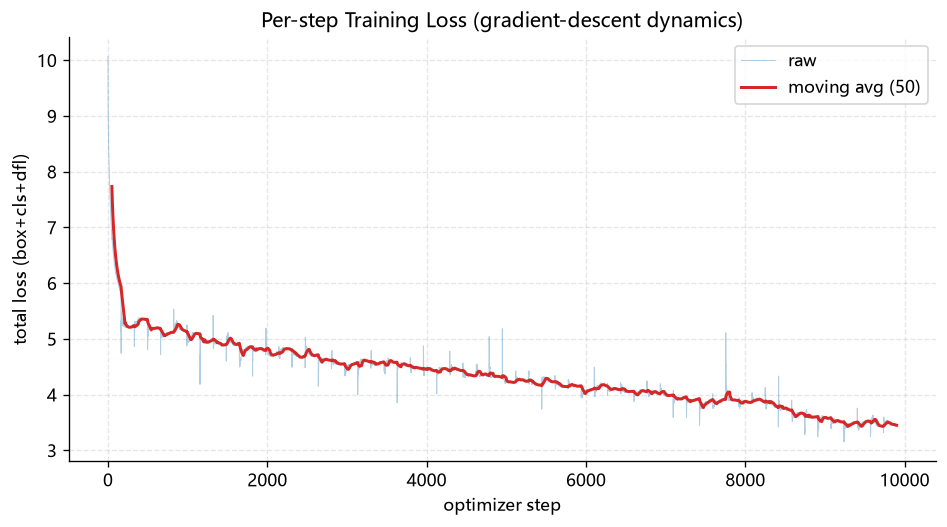

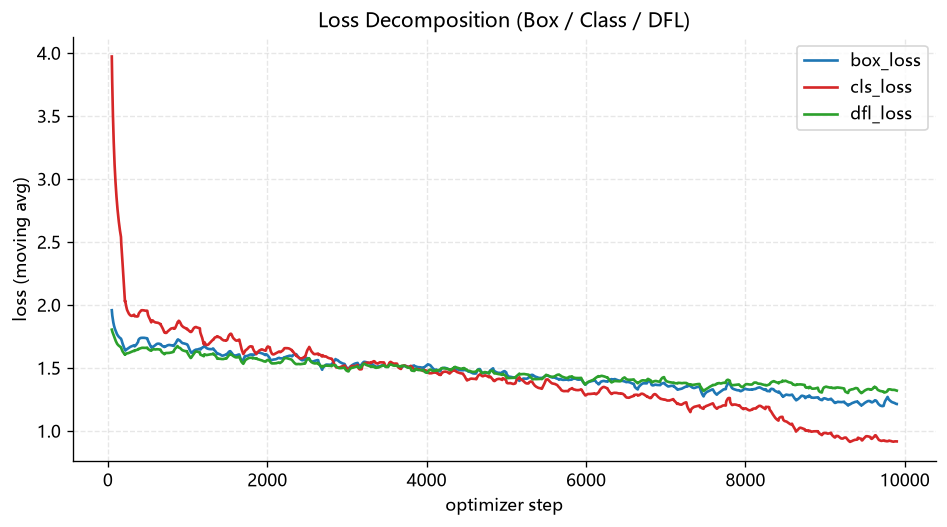

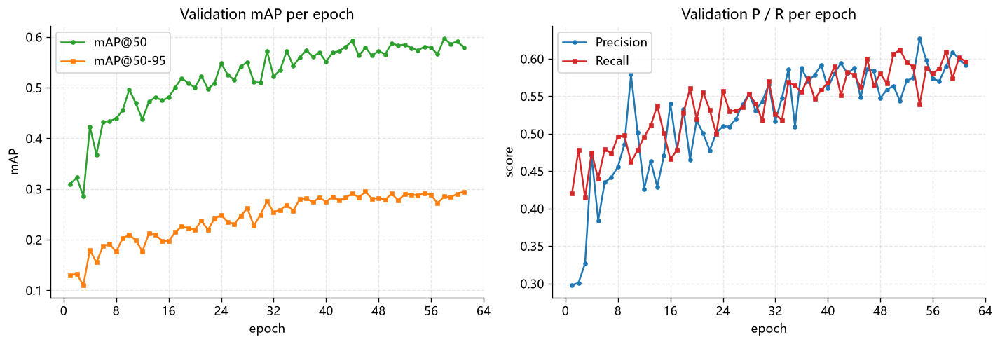

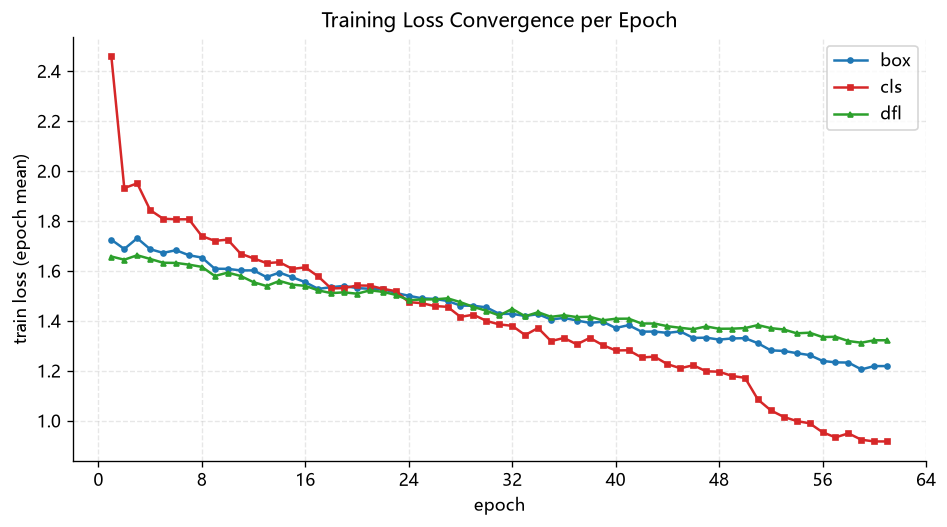

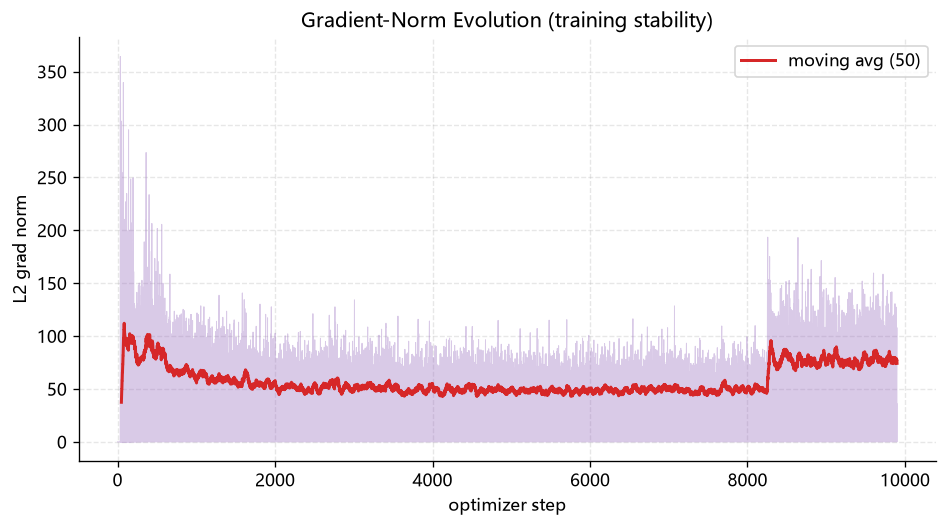

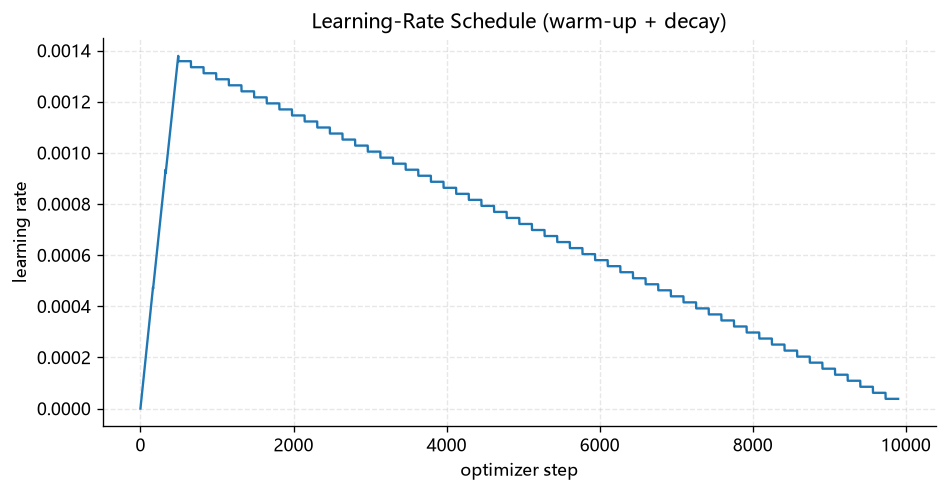

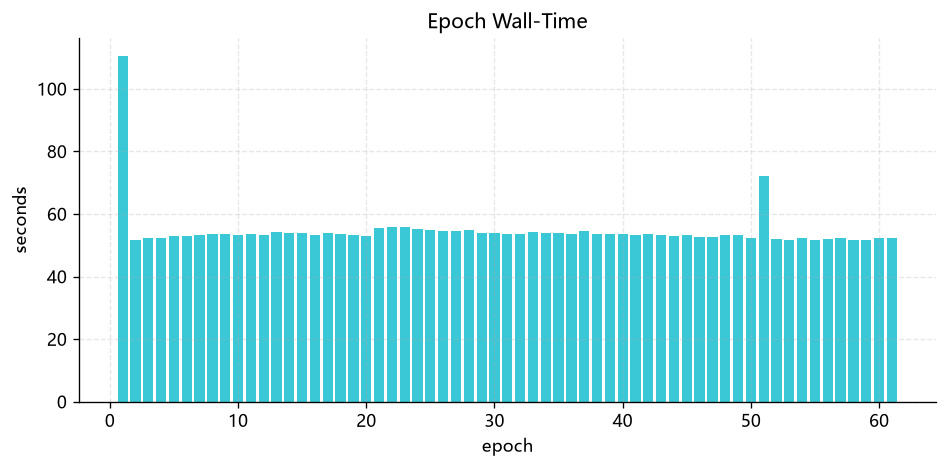

已生成训练曲线：
  step_loss      -> figs\curve_step_loss.png
  loss_decomp    -> figs\curve_step_loss_decomposed.png
  epoch_metrics  -> figs\curve_epoch_metrics.png
  epoch_loss     -> figs\curve_epoch_loss.png
  grad_norm      -> figs\curve_grad_norm.png
  lr             -> figs\curve_lr_schedule.png
  epoch_time     -> figs\bars_epoch_time.png


In [11]:
plt.ioff()  # 批量出图（不逐张交互刷新）
curve_paths = RT.plot_training_curves(HIST, "figs") if len(HIST) else {}
plt.ion()
print("已生成训练曲线：")
for k, p in curve_paths.items():
    print(f"  {k:14s} -> {p}")

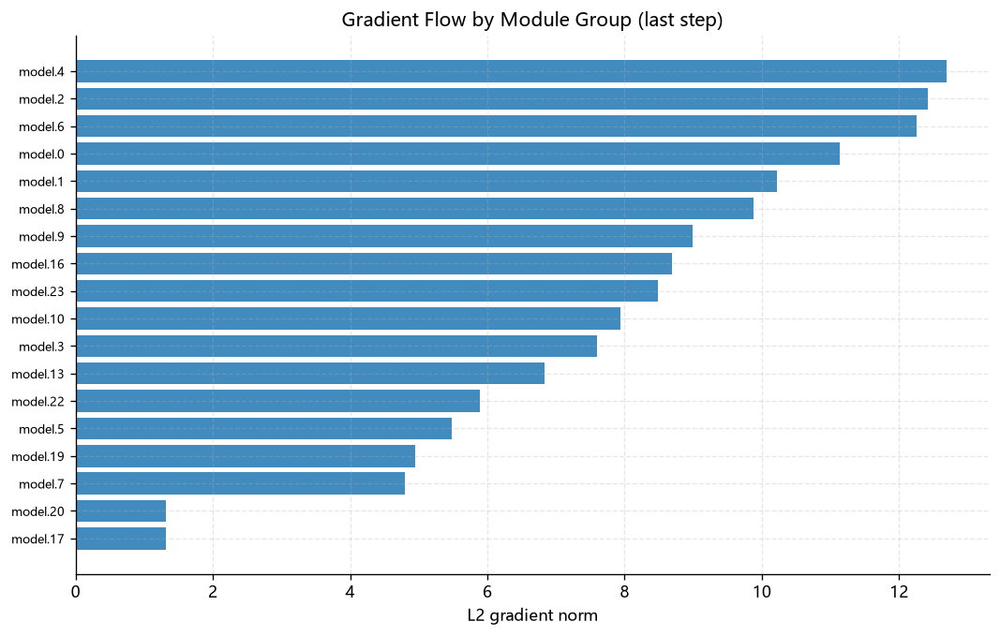

逐层梯度流： figs\bar_grad_norm_by_layer.png


In [12]:
# 图 5.7 逐层梯度流
plt.ioff()
grad_layer_path = RT.plot_gradient_norms_by_layer(HIST, "figs")
plt.ion()
print("逐层梯度流：", grad_layer_path)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
55,56,3071.24,1.23946,0.95386,1.33487,0.57341,0.58073,0.57869,0.28811,1.72310,1.50656,1.76118,0.000132,0.000132,0.000132
56,57,3123.56,1.23367,0.93324,1.33621,0.57027,0.58674,0.56595,0.27184,1.74163,1.51584,1.77161,0.000109,0.000109,0.000109
57,58,3175.25,1.23288,0.94939,1.31899,0.58982,0.60942,0.59721,0.28571,1.73918,1.47854,1.77240,0.000085,0.000085,0.000085
58,59,3227.04,1.20550,0.92390,1.31239,0.60867,0.57365,0.58615,0.28382,1.74480,1.47552,1.76920,0.000061,0.000061,0.000061
59,60,3279.48,1.21880,0.91701,1.32216,0.60030,0.60161,0.59183,0.29065,1.71672,1.44781,1.75603,0.000038,0.000038,0.000038


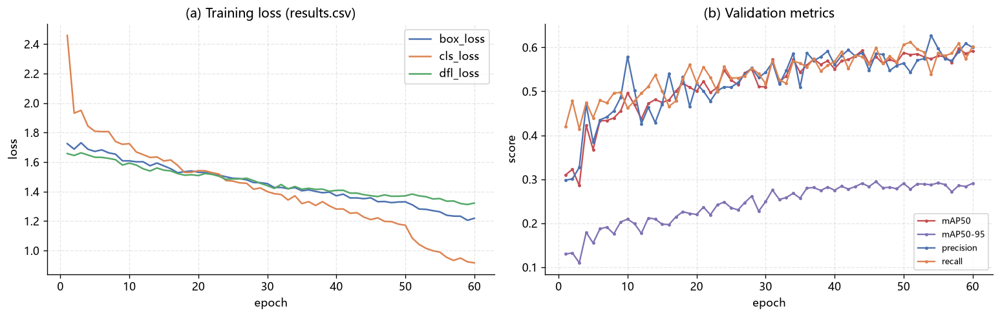

In [13]:
# ---- 用 Ultralytics 自动生成的 results.csv 复绘论文版 loss/mAP 曲线 ----
csv_path = RUN_DIR / "results.csv"
if csv_path.exists():
    res_df = pd.read_csv(csv_path)
    res_df.columns = [c.strip() for c in res_df.columns]
    display(res_df.tail())

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for col, c in [("train/box_loss", "#4C72B0"), ("train/cls_loss", "#DD8452"), ("train/dfl_loss", "#55A868")]:
        if col in res_df: axes[0].plot(res_df["epoch"], res_df[col], "-", color=c, lw=1.5, label=col.split("/")[1])
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
    axes[0].set_title("(a) Training loss (results.csv)")
    for col, c in [("metrics/mAP50(B)", "#C44E52"), ("metrics/mAP50-95(B)", "#8172B3"),
                   ("metrics/precision(B)", "#4C72B0"), ("metrics/recall(B)", "#DD8452")]:
        if col in res_df:
            sub = res_df[col]
            axes[1].plot(res_df["epoch"][sub > 0], sub[sub > 0], "-o", ms=2, color=c, lw=1.4,
                         label=col.split("(")[0].split("/")[1])
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("score"); axes[1].legend(fontsize=8)
    axes[1].set_title("(b) Validation metrics")
    plt.tight_layout(); plt.savefig("figs/curve_results_csv.png", bbox_inches="tight"); plt.show()
else:
    print("未找到 results.csv（训练中断或未启用绘图）。")

## 6. 模型评价

在验证集 / 测试集上评估最佳权重，输出：
- 总体与逐类 **Precision / Recall / F1 / mAP@50 / mAP@50-95**；
- **混淆矩阵**（列归一化）；
- **Precision-Confidence 与 F1-Confidence** 曲线；
- **检测结果画廊**（真实框 vs 预测框对比）；
- Ultralytics 自带验证图（PR / P-R / F1 曲线、val batch 预测）。

In [14]:
# ---- 6.1 验证集 / 测试集定量评价 ----
best_model = YOLO(str(BEST))
_, val_report = RT.evaluate_model(best_model, DATA_YAML, split="val", imgsz=CFG["imgsz"], device=DEVICE)
test_model = YOLO(str(BEST))
_, test_report = RT.evaluate_model(test_model, DATA_YAML, split="test", imgsz=CFG["imgsz"], device=DEVICE)

def report_to_df(rep):
    rows = [{"class": "ALL", **rep["overall"]}]
    for c, d in rep["per_class"].items():
        rows.append({"class": c, "precision": d["precision"], "recall": d["recall"],
                     "f1": np.nan, "map50": d["ap50"], "map": d["ap"], "mp": np.nan, "mr": np.nan})
    return pd.DataFrame(rows)

print("=== 验证集 (val) ==="); display(report_to_df(val_report).round(4))
print("=== 测试集 (test) ==="); display(report_to_df(test_report).round(4))

report_to_df(val_report).to_csv("figs/metrics_val.csv", index=False)
report_to_df(test_report).to_csv("figs/metrics_test.csv", index=False)
json.dump({"val": val_report, "test": test_report, "train_seconds": train_seconds, "config": CFG},
          open("figs/metrics_full.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("指标已保存：figs/metrics_val.csv / metrics_test.csv / metrics_full.json")

Ultralytics 8.4.202  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA T1200 Laptop GPU, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 464.3±237.7 MB/s, size: 90.2 KB)
val: Scanning C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\datasets\rockfall\labels\val.cache... 390 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 390/390  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.2it/s 21.7s0.2s
                   all        390        814      0.602       0.59      0.586      0.293
              rockfall        154        476      0.554      0.621      0.619      0.364
            landslides        322        338      0.649      0.559      0.553      0.222
Speed: 0.8ms preprocess, 6.1ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\runs\detect\val
Ultraly

,class,precision,recall,f1,map50,map,mp,mr
0,ALL,0.6017,0.5899,0.5932,0.5858,0.2930,0.6017,0.5899
1,rockfall,0.5540,0.6210,NaN,0.6191,0.3641,NaN,NaN
2,landslides,0.6494,0.5589,NaN,0.5525,0.2218,NaN,NaN


=== 测试集 (test) ===


,class,precision,recall,f1,map50,map,mp,mr
0,ALL,0.6620,0.5496,0.5972,0.6051,0.3012,0.662,0.5496
1,rockfall,0.5811,0.5656,NaN,0.6062,0.3561,NaN,NaN
2,landslides,0.7429,0.5337,NaN,0.6039,0.2462,NaN,NaN


指标已保存：figs/metrics_val.csv / metrics_test.csv / metrics_full.json


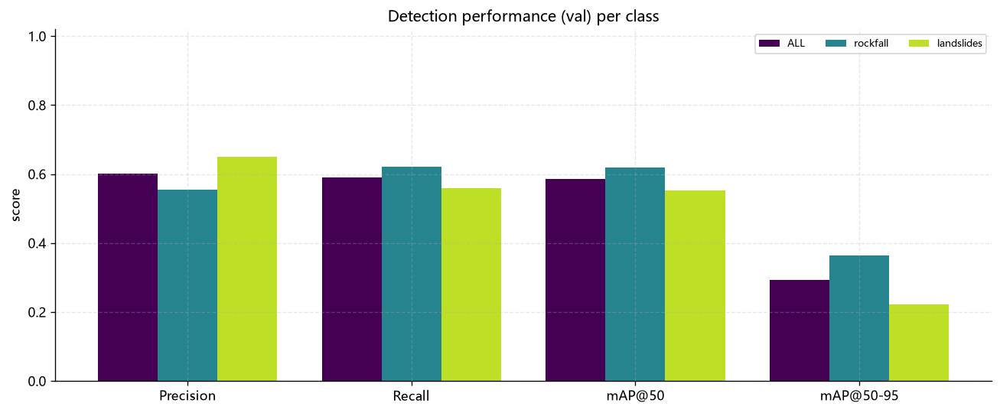

In [15]:
# ---- 6.2 指标柱状图（总体 + 逐类）----
dv = report_to_df(val_report)
metrics = ["precision", "recall", "map50", "map"]
labels = ["Precision", "Recall", "mAP@50", "mAP@50-95"]
x = np.arange(len(metrics)); width = 0.8 / max(len(dv), 1)
fig, ax = plt.subplots(figsize=(11, 4.6))
cmap = plt.cm.viridis(np.linspace(0, 0.9, len(dv)))
for i, (_, row) in enumerate(dv.iterrows()):
    vals = [row.get(m, 0) if not pd.isna(row.get(m, np.nan)) else 0 for m in metrics]
    ax.bar(x + i * width, vals, width, label=row["class"], color=cmap[i])
ax.set_xticks(x + width * (len(dv) - 1) / 2); ax.set_xticklabels(labels)
ax.set_ylabel("score"); ax.set_ylim(0, 1.02); ax.set_title("Detection performance (val) per class")
ax.legend(fontsize=8, ncol=len(dv))
plt.tight_layout(); plt.savefig("figs/metrics_bar.png", bbox_inches="tight"); plt.show()

Ultralytics 8.4.202  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA T1200 Laptop GPU, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1530.0±487.8 MB/s, size: 309.8 KB)
val: Scanning C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\datasets\rockfall\labels\test.cache... 258 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 258/258  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 1.1s/it 18.5s0.1s
                   all        258        710      0.654      0.548        0.6      0.304
Speed: 0.8ms preprocess, 5.5ms inference, 0.0ms loss, 0.8ms postprocess per image


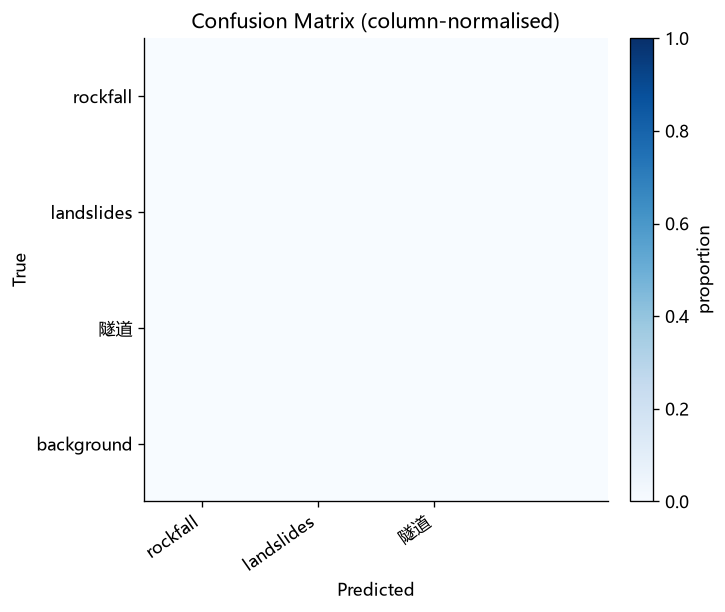

混淆矩阵： figs\confusion_matrix.png


In [16]:
# ---- 6.3 混淆矩阵（列归一化）----
cm = YOLO(str(BEST)).val(data=str(DATA_YAML), split="test", imgsz=CFG["imgsz"],
                         device=DEVICE, plots=False, verbose=False)
cm_path = RT.plot_confusion_matrix(cm.confusion_matrix.matrix, cm.names, "figs", normalize=True)
print("混淆矩阵：", cm_path)

In [17]:
# ---- 6.4 Precision-Confidence / F1-Confidence 曲线 ----
p_pr, p_f1 = RT.plot_pr_f1_curves(cm, "figs")
print("Precision-Confidence 曲线：", p_pr)
print("F1-Confidence 曲线：", p_f1)

Precision-Confidence 曲线： None
F1-Confidence 曲线： None


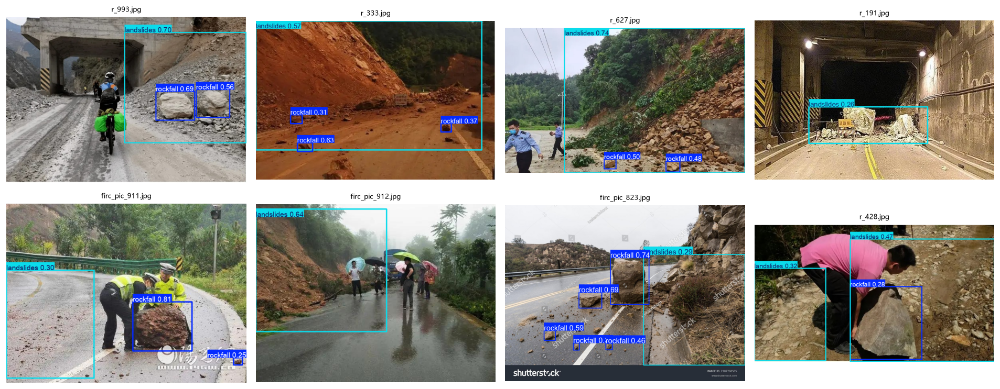

检测画廊： figs\detection_gallery.png | 图片数： 8


In [18]:
# ---- 6.5 检测结果画廊（真实框 vs 预测框）----
gallery, preds = RT.plot_detection_gallery(best_model, DATA_ROOT / "images" / "test",
                                           "figs", imgsz=CFG["imgsz"], conf=0.25, max_images=8, seed=SEED)
print("检测画廊：", gallery, "| 图片数：", len(preds))

Ultralytics 8.4.202  Python-3.12.10 torch-2.6.0+cu124 CUDA:0 (NVIDIA T1200 Laptop GPU, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,597,537 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 522.9±183.2 MB/s, size: 63.2 KB)
val: Scanning C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\datasets\rockfall\labels\val.cache... 390 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 390/390  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.3it/s 19.8s0.2s
                   all        390        814      0.591      0.597      0.579      0.295
Speed: 0.8ms preprocess, 5.8ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\runs\detect\val-4
Ultralytics 验证图表目录： C:\Users\30353\Desktop\桌面整理\02_科研与AI项目\rockfall\runs\detect\val-4


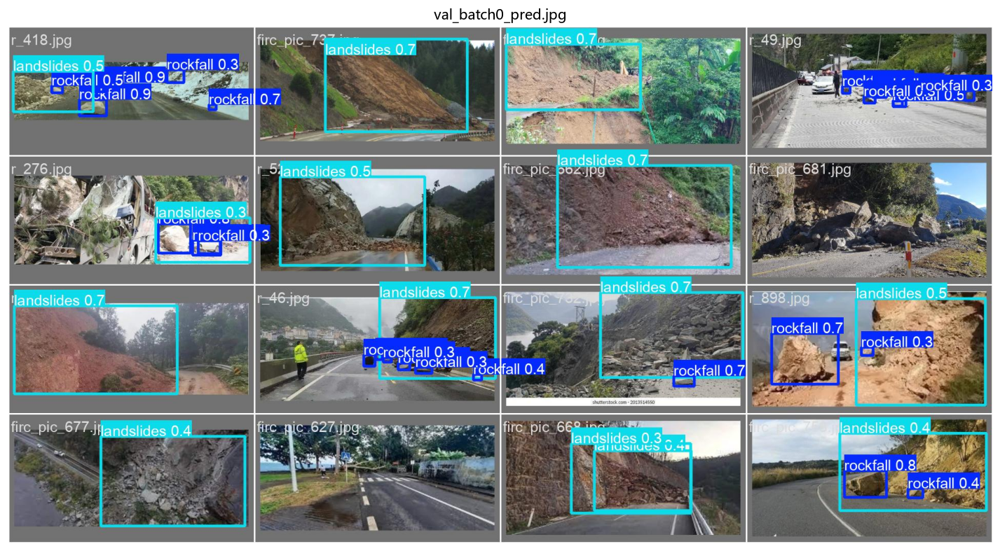

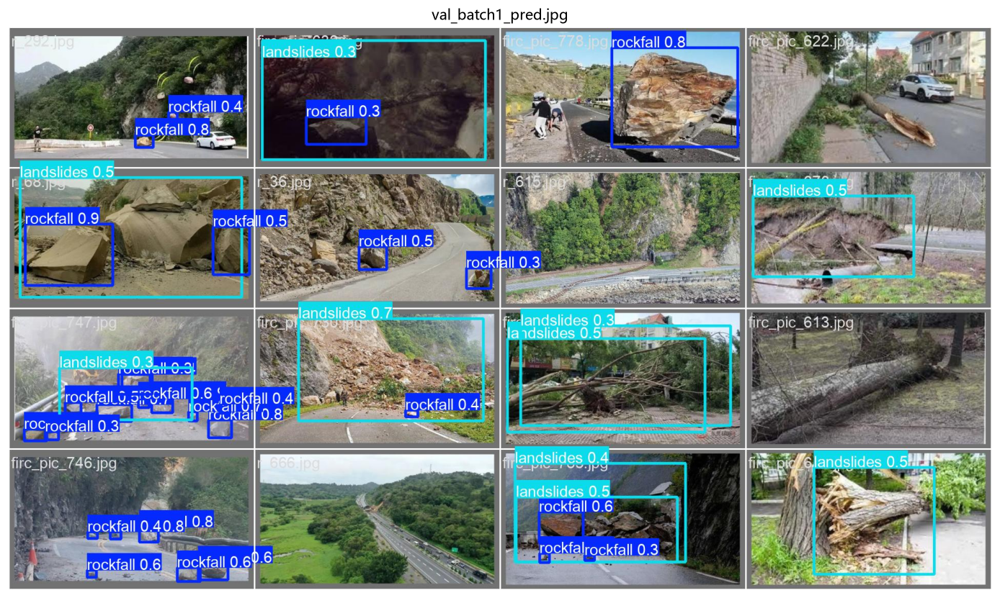

In [19]:
# ---- 6.6 复用 Ultralytics 自带验证可视化（val batch 预测图等）----
vall_res = YOLO(str(BEST)).val(data=str(DATA_YAML), split="val", imgsz=CFG["imgsz"],
                               device=DEVICE, plots=True, verbose=False)
print("Ultralytics 验证图表目录：", Path(vall_res.save_dir))
for pat in ["val_batch0_pred.jpg", "val_batch1_pred.jpg"]:
    fp = Path(vall_res.save_dir) / pat
    if fp.exists():
        plt.figure(figsize=(12, 7)); plt.imshow(plt.imread(fp)); plt.axis("off")
        plt.title(pat); plt.show()

## 7. 结果汇总与论文图表清单

汇总关键指标与已保存的高分辨率图表，便于直接写入论文。

In [20]:
summary = {
    "dataset": {"train": int(df_split.loc[0, 'images']), "val": int(df_split.loc[1, 'images']),
                "test": int(df_split.loc[2, 'images']), "classes": CLASSES},
    "model": CFG["model"], "imgsz": CFG["imgsz"], "epochs": CFG["epochs"],
    "train_minutes": round(train_seconds / 60, 1),
    "val": val_report["overall"], "test": test_report["overall"],
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

print("\n=== 论文可用图表清单（figs/）===")
for p in sorted(Path("figs").glob("*.png")):
    print(" -", p, f"({p.stat().st_size/1024:.0f} KB)")

{
  "dataset": {
    "train": 1316,
    "val": 390,
    "test": 258,
    "classes": [
      "rockfall",
      "landslides",
      "隧道"
    ]
  },
  "model": "yolo11n.pt",
  "imgsz": 640,
  "epochs": 60,
  "train_minutes": 54.9,
  "val": {
    "precision": 0.6016689877955439,
    "recall": 0.5899434875198767,
    "f1": 0.5931579094398396,
    "map50": 0.585827830653744,
    "map": 0.29297204789593134,
    "mp": 0.6016689877955439,
    "mr": 0.5899434875198767
  },
  "test": {
    "precision": 0.6620125576593773,
    "recall": 0.5496379881983963,
    "f1": 0.5972011684542458,
    "map50": 0.6050825923754108,
    "map": 0.30115284878897347,
    "mp": 0.6620125576593773,
    "mr": 0.5496379881983963
  }
}

=== 论文可用图表清单（figs/）===
 - figs\bar_grad_norm_by_layer.png (137 KB)
 - figs\bars_epoch_time.png (63 KB)
 - figs\confusion_matrix.png (89 KB)
 - figs\curve_epoch_loss.png (151 KB)
 - figs\curve_epoch_metrics.png (286 KB)
 - figs\curve_grad_norm.png (170 KB)
 - figs\curve_lr_schedule.png (1